# MASW Analysis — Line L1

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import seg2_io, masw, plotting

# --- Data ---
DATA_FOLDER = "L1/MASW"
# Fix wrong SEG-2 header geometry per file, e.g. {"2026-10-08_MW_-6m.dat": -6.0}
SOURCE_X_OVERRIDES = {}

# --- Dispersion imaging (phase-shift transform) ---
C_MIN, C_MAX, C_STEP = 50.0, 800.0, 2.5   # m/s, phase velocities to scan
F_MIN, F_MAX = 5.0, 100.0                 # Hz, frequency band of the image

# --- Fundamental-mode picking ---
F_PICK_MIN, F_PICK_MAX = 12.0, 60.0       # Hz, band where the mode is picked
SMOOTH_POINTS = 5                         # moving-average length for the curve

# --- Vs profile ---
DEPTH_FACTOR = 2.5     # pseudo-depth z = wavelength / DEPTH_FACTOR
VS_FACTOR = 1.09       # Vs = VS_FACTOR x c_R (Poisson's ratio ~ 0.35)
Z_MAX = 8.0           # m, maximum profile depth
LAYER_BOUNDARIES = [2.0, 6.0]   # m, depths separating the layer model
# Picks with wavelength < 2 x receiver spacing are spatially aliased: the
# phase-shift image has slow alias peaks of similar energy (None keeps all).
MIN_WAVELENGTH = 10.0  # m (receivers every 5 m)

OUTPUT_CSV = "L1/MASW_vs_profile.csv"
OUTPUT_PROFILE_PNG = "L1/MASW_profile_1d.png"

## 1. Load shot gathers

Read 2 shot gathers from L1/MASW:
  2026-10-08_MW_-6m.dat: source at -5.0 m, 12 receivers (0.0-55.0 m), 2048 samples at 2000 Hz
  2026-10-08_MW_60m.dat: source at +60.0 m, 12 receivers (0.0-55.0 m), 2048 samples at 2000 Hz


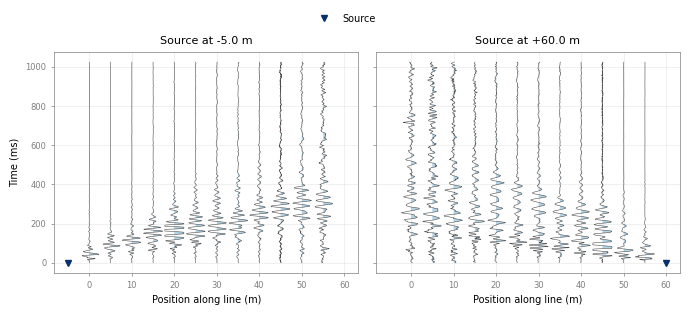

In [2]:
gathers = seg2_io.read_line(DATA_FOLDER, source_x_overrides=SOURCE_X_OVERRIDES)
plotting.plot_all_gathers(gathers)
plt.show()

## 2. Dispersion imaging & fundamental-mode picking

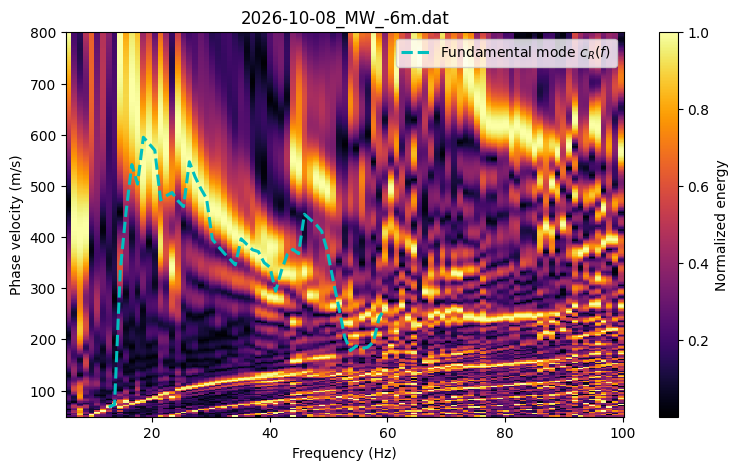

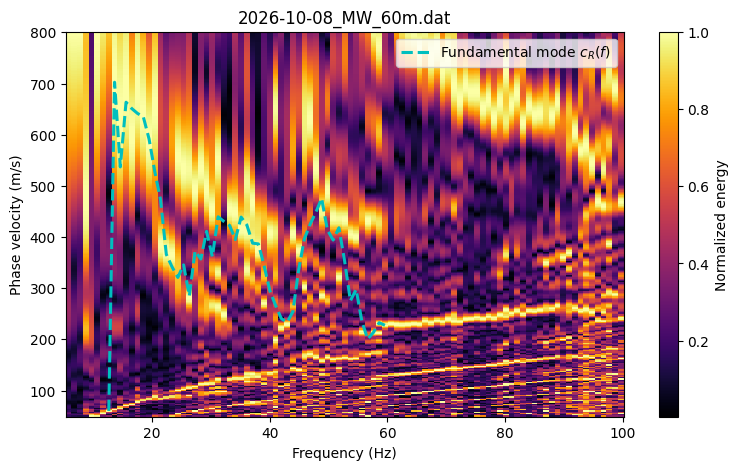

In [3]:
curves = []
for gather in gathers:
    f, c, energy = masw.dispersion_image(
        gather, c_min=C_MIN, c_max=C_MAX, c_step=C_STEP,
        f_min=F_MIN, f_max=F_MAX,
    )
    curve = masw.pick_dispersion_curve(
        f, c, energy, f_min=F_PICK_MIN, f_max=F_PICK_MAX,
        smooth_points=SMOOTH_POINTS,
    )
    curves.append(curve)
    masw.plot_dispersion(f, c, energy, curve, title=gather.filename)
plt.show()

## 3. Averaged dispersion curve

In [4]:
curve_mean = masw.average_curves(curves)
curve_mean.round(2)

,frequency_Hz,c_rayleigh_m_s,wavelength_m
0,12.70,63.75,5.02
1,13.67,387.50,28.34
2,14.65,436.00,29.76
3,15.62,556.25,35.60
4,16.60,596.25,35.92
5,17.58,572.50,32.57
6,18.55,615.00,33.15
7,19.53,587.00,30.05
8,20.51,548.50,26.75
9,21.48,472.50,21.99


## 4. Vs depth profile & layer model

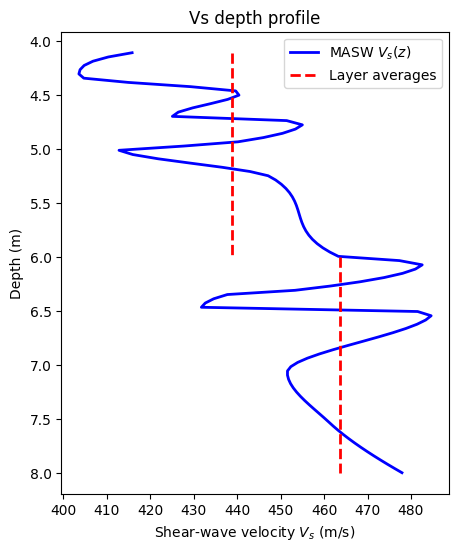

,top_m,bottom_m,vs_mean_m_s
0,4.11,6.0,438.9
1,6.00,8.0,463.6


In [5]:
profile_kwargs = dict(depth_factor=DEPTH_FACTOR, vs_factor=VS_FACTOR,
                      min_wavelength=MIN_WAVELENGTH)
profile = masw.vs_profile(curve_mean, z_max=Z_MAX, **profile_kwargs)
profile = masw.add_shot_profiles(profile, curves, **profile_kwargs)
layers = masw.layer_averages(profile, LAYER_BOUNDARIES)
masw.plot_vs_profile(profile, layers)
plt.show()
layers

### 4.1 1D Vs profile

Mean Vs (thin lines: single shots) and Vs-class layers. Crosses: picks with λ < 2Δx, left out because they are spatially aliased. Indicative only.

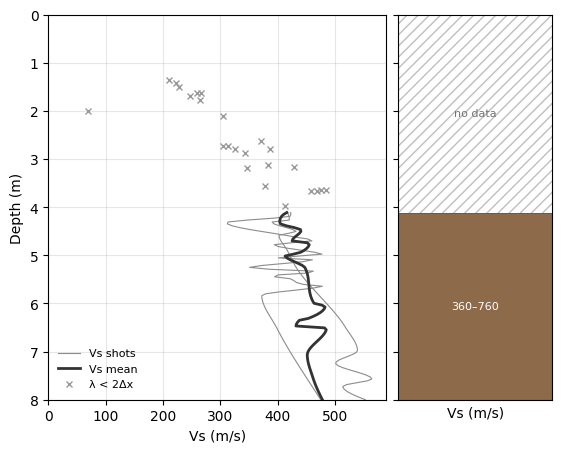

,top_m,bottom_m,vs_mean_m_s,class
0,4.11,8.0,451.46,2


In [6]:
flagged = masw.aliased_picks(curve_mean, MIN_WAVELENGTH, DEPTH_FACTOR, VS_FACTOR)
flagged = flagged[flagged["depth_m"] <= Z_MAX]
vs_fig, vs_layers = plotting.plot_1d_vs_profile(profile, flagged)
vs_fig.savefig(OUTPUT_PROFILE_PNG, dpi=180, bbox_inches="tight")
plt.show()
pd.DataFrame(vs_layers).round(2)

## 5. Export

In [7]:
profile.to_csv(OUTPUT_CSV, index=False)
print(f"Vs profile saved to {OUTPUT_CSV}")

Vs profile saved to L1/MASW_vs_profile.csv
